# Linear Regression from Scratch

*By Shikha Pallavi*

How does a model find the best-fit line? In this notebook we build it step by step: measure the error, define a cost function, and let **gradient descent** shrink that cost. Then we check our result against scikit-learn.

> ## 📖 Read the full series: [Machine Learning Basics](https://shikhapallavi123.github.io/ml-basics/)
> This notebook is the hands-on companion to **Part 3**. Read it first for the visual explanation, then run the code here.
> [Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html)

**What you'll learn**
1. The hypothesis function `h(x) = θ0 + θ1·x`
2. The cost function (mean squared error)
3. Gradient descent, the loop that updates θ0 and θ1
4. How scikit-learn gets the same answer in one line

## 1. The data

Five students: hours studied (x) and exam score out of 100 (y). We want to predict a score from study hours.

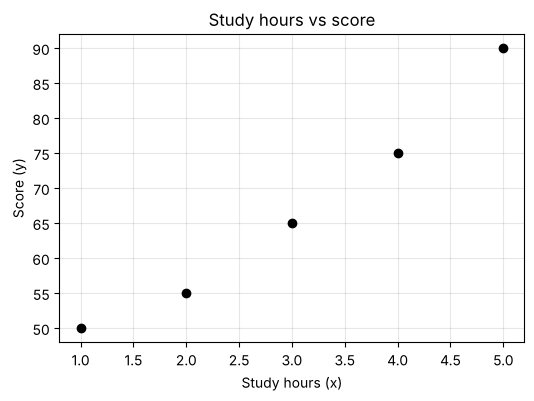

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1, 2, 3, 4, 5], dtype=float)      # study hours (the feature)
y = np.array([50, 55, 65, 75, 90], dtype=float) # exam score (what we predict)
m = len(x)                                      # number of data points

plt.figure(figsize=(6, 4))
plt.scatter(x, y, color="black", zorder=3)
plt.xlabel("Study hours (x)")
plt.ylabel("Score (y)")
plt.title("Study hours vs score")
plt.grid(alpha=0.3)
plt.show()

## 2. The hypothesis function

A straight line is `y = c + m·x`. In ML notation we write it as

**h(x) = θ0 + θ1·x**

- `θ0` is the **bias** (intercept)
- `θ1` is the **coefficient** (slope)
- `x` is the **feature**

Different values of θ0 and θ1 give different lines. Our job is to find the best pair.

In [2]:
def h(theta0, theta1, x):
    """Hypothesis: the line's prediction for each x."""
    return theta0 + theta1 * x

# Two guesses: a poor line and a good line
for t0, t1 in [(60, 4), (37, 10)]:
    print(f"h(x) = {t0} + {t1}x -> predictions {h(t0, t1, x)}")

h(x) = 60 + 4x -> predictions [64. 68. 72. 76. 80.]
h(x) = 37 + 10x -> predictions [47. 57. 67. 77. 87.]


## 3. The cost function

The **error** (residual) of one point is *actual − predicted*. To score a whole line we need one number, so we use the **mean squared error** with a factor of ½:

**J(θ) = 1 / (2m) · Σ ( h(x⁽ⁱ⁾) − y⁽ⁱ⁾ )²**

Squaring stops positive and negative errors from cancelling out and punishes big misses more. The ½ only makes the derivative cleaner later.

In [3]:
def cost(theta0, theta1, x, y):
    errors = h(theta0, theta1, x) - y
    return (errors ** 2).sum() / (2 * len(x))

print("J for h(x) = 60 + 4x :", round(cost(60, 4, x, y), 2))
print("J for h(x) = 37 + 10x:", round(cost(37, 10, x, y), 2))
print("J for h(x) = 0 + 0x  :", round(cost(0, 0, x, y), 2))

J for h(x) = 60 + 4x : 51.5
J for h(x) = 37 + 10x: 3.0
J for h(x) = 0 + 0x  : 2347.5


A smaller J means a better line. Now we want to *search* for the θ values that make J as small as possible.

## 4. Gradient descent

The loop from the slides:

1. Start with initial values for θ0 and θ1
2. Compute J(θ)
3. Update θ0 and θ1 so that J gets smaller
4. Repeat

The update uses the slope (gradient) of J. With learning rate **α**:

```
θ0 := θ0 − α · (1/m) Σ ( h(x) − y )
θ1 := θ1 − α · (1/m) Σ ( h(x) − y ) · x
```

In [4]:
def gradient_descent(x, y, alpha=0.05, steps=2000):
    theta0, theta1 = 0.0, 0.0          # initial guess
    history = []
    for _ in range(steps):
        errors = h(theta0, theta1, x) - y
        grad0 = errors.mean()
        grad1 = (errors * x).mean()
        theta0 -= alpha * grad0         # update both together
        theta1 -= alpha * grad1
        history.append(cost(theta0, theta1, x, y))
    return theta0, theta1, history

theta0, theta1, history = gradient_descent(x, y)
print(f"theta0 (bias)        = {theta0:.2f}")
print(f"theta1 (coefficient) = {theta1:.2f}")
print(f"final cost J         = {history[-1]:.2f}")
print(f"prediction for 2.5 hours: {h(theta0, theta1, 2.5):.1f}")

theta0 (bias)        = 37.00
theta1 (coefficient) = 10.00
final cost J         = 3.00
prediction for 2.5 hours: 62.0


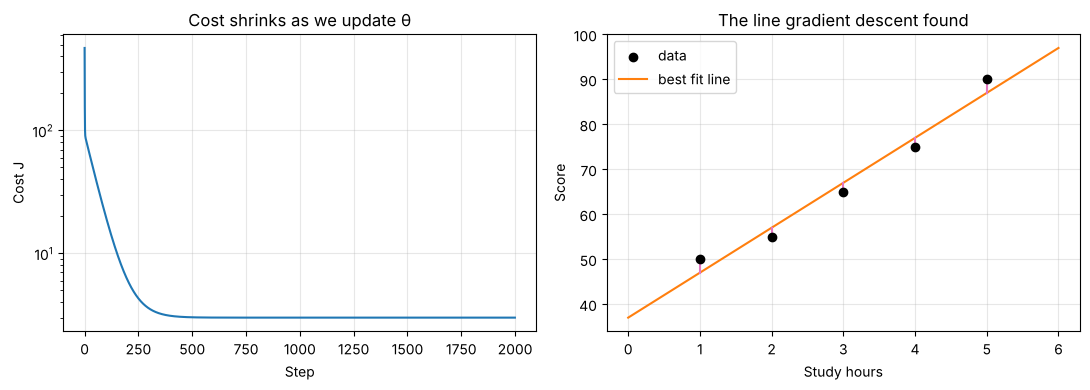

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history)
ax[0].set_xlabel("Step")
ax[0].set_ylabel("Cost J")
ax[0].set_title("Cost shrinks as we update θ")
ax[0].set_yscale("log")
ax[0].grid(alpha=0.3)

xs = np.linspace(0, 6, 50)
ax[1].scatter(x, y, color="black", zorder=3, label="data")
ax[1].plot(xs, h(theta0, theta1, xs), color="tab:orange", label="best fit line")
for xi, yi in zip(x, y):
    ax[1].plot([xi, xi], [yi, h(theta0, theta1, xi)], color="tab:pink", lw=1.5)
ax[1].set_xlabel("Study hours")
ax[1].set_ylabel("Score")
ax[1].set_title("The line gradient descent found")
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

The cost drops fast at first, then flattens as we reach the bottom. The pink lines are the remaining errors.

### What if the step size is wrong?

The learning rate α matters. Too small is safe but slow. Too large overshoots and the cost *grows*.

In [6]:
for alpha in [0.001, 0.05, 0.2]:
    _, _, hist = gradient_descent(x, y, alpha=alpha, steps=200)
    status = "diverged!" if hist[-1] > hist[0] else "converging"
    print(f"alpha = {alpha:<6} cost after 200 steps = {hist[-1]:>12.3g}  ({status})")

alpha = 0.001  cost after 200 steps =          108  (converging)
alpha = 0.05   cost after 200 steps =         6.08  (converging)
alpha = 0.2    cost after 200 steps =     3.61e+57  (diverged!)


## 5. Check against scikit-learn

scikit-learn solves the same problem for us. The numbers should match.

In [7]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(x.reshape(-1, 1), y)   # sklearn expects a 2D feature array
print(f"sklearn intercept (θ0): {model.intercept_:.2f}")
print(f"sklearn coefficient (θ1): {model.coef_[0]:.2f}")
print(f"sklearn prediction for 2.5 hours: {model.predict([[2.5]])[0]:.1f}")
print()
print(f"our θ0 = {theta0:.2f}, our θ1 = {theta1:.2f}")

sklearn intercept (θ0): 37.00
sklearn coefficient (θ1): 10.00
sklearn prediction for 2.5 hours: 62.0

our θ0 = 37.00, our θ1 = 10.00


## Key takeaways

- **Hypothesis:** `h(x) = θ0 + θ1·x` is the model's guess.
- **Cost function:** mean squared error turns "how wrong is this line?" into one number.
- **Gradient descent:** repeat *compute cost → update θ* until the cost stops shrinking.
- **Learning rate:** too big overshoots, too small is slow.
- **scikit-learn** gives the same answer, but now you know what happens inside `fit()`.

## 📖 Continue the series
**[Read all of Machine Learning Basics →](https://shikhapallavi123.github.io/ml-basics/)**
[Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html)

---
*© 2026 Shikha Pallavi. Shared under the Apache 2.0 license. You are welcome to reuse the code. Please credit the author and link back to the Machine Learning Basics series.*